# Warm start vs cold restart of the committor training

In the AIMMD-TIS loop, each new model $q_{k+1}$ is trained on the reweighted path ensemble RPE$_k$, **warm-started** from $q_k$. This notebook tests whether that matters. Using the *same* training sets, each $q_{k+1}$ is retrained from a **cold restart** (a fresh network with the same architecture, the same stochastic gates and the same training settings), and the two models are compared side by side.

No new sampling is done: the TIS paths, and so the training sets, are those of the warm-started run. This test isolates the training. It doesn't test how a cold-restarted model would steer the interfaces and the sampling of a later iteration.

Produce the cold-restart models with:
```bash
python extras/retrain_control.py --out results_harmonics20 --iterations 0-11 --init scratch --with-original
python extras/retrain_control.py --out results_harmonics20 --iterations 0-11 --init scratch --variant lr_1e-3 --with-original
```
The first cold restart uses the run's training settings unchanged (base_lr 1e-4). The second differs only in base_lr = 1e-3.
Both models are evaluated on the same analysis set `rpe_it{k}/rpe_analysis.npz` against the exact committor.

**What to look for:**
- **Accuracy:** does the cold-restart model reach the same error against the exact committor? If not, the warm start carries information that one training on RPE$_k$ can't recover.
- **Stability:** a warm start should change the model only where RPE$_k$ adds information. A cold-restarted model may move around between iterations even where the data barely changed.
- **Cost:** epochs to the early stop.
- **Gates (22-D):** whether both models keep x and y open and close the 20 harmonic noise dimensions.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import warnings

import aimmd
import run_iterative as ri
import diagnostics as dg

warnings.filterwarnings("ignore", category=RuntimeWarning)

OUT = Path("results_harmonics20")                  # run folder (warm-started models)
# Cold-restart variants from retrain_control.py (label -> folder); missing ones are skipped.
COLD = {"cold, lr 1e-4": OUT / "control" / "default_scratch",
        "cold, lr 1e-3": OUT / "control" / "lr_1e-3_scratch"}
COLD = {name: d for name, d in COLD.items() if (d / "metrics.csv").exists()}

cfg = ri.load_run_config(OUT)
acfg = cfg["analysis"]
with dg.quiet():
    wf = ri.IterativeAimmdTIS(cfg, OUT, n_workers=1)
theory_path = wf.theory_path()

ITS = sorted(set.intersection(*(set(int(p.stem.split("_it")[1]) for p in d.glob("metrics_it*.json"))
                                 for d in COLD.values())))
LAST = ITS[-1]
SHOW = sorted({ITS[0], 1, min(4, LAST), LAST} & set(ITS))
NAMES = ["warm"] + list(COLD)
COLORS = dict(zip(NAMES, ["C0", "C3", "C2", "C4"]))
HIST = {"warm": OUT / "models", **COLD}   # training_it{k+1}.json per model

_cold = {}
def cold_model(name, k):
    """Cold-restart q_{k+1} of variant ``name``, trained from scratch on RPE_k."""
    if (name, k) not in _cold:
        store = aimmd.Storage(str(COLD[name] / f"aimmd_it{k + 1}.h5"), "r")
        model = store.rcmodels["most_recent"]
        store.close()
        model.nnet.to("cpu").eval()
        _cold[name, k] = model
    return _cold[name, k]

def models(k):
    """All versions of q_{k+1}: the run's warm-started one and each cold restart."""
    return {"warm": wf.load_model(k + 1), **{name: cold_model(name, k) for name in COLD}}

_vis = {}
def vis_of(k):
    if k not in _vis:
        with dg.quiet():
            _vis[k] = dg.load_iteration(wf, k)[0]
    return _vis[k]

print(f"models: {NAMES}; {len(ITS)} training sets (iterations {ITS[0]}-{LAST}); showing {SHOW}")

fatal: not a git repository (or any of the parent directories): .git


models: ['warm', 'cold, lr 1e-4', 'cold, lr 1e-3']; 12 training sets (iterations 0-11); showing [0, 1, 4, 11]


## 1. Accuracy against the exact committor, per iteration
Both models are scored on the same RPE$_k$ bins: the logit RMSE (for $|q_{exact}|<10$) and the $p_B$ RMSE against the exact committor, the median calibration error against the RPE shot results, and roughness (the RMS error of the Laplacian of $q$ against the exact one).

**What to look for:** if the cold-restart curve lies on top of the warm one, one training on RPE$_k$ is enough and the warm start only saves time. If it lies above, the warm start carries over structure from earlier ensembles.

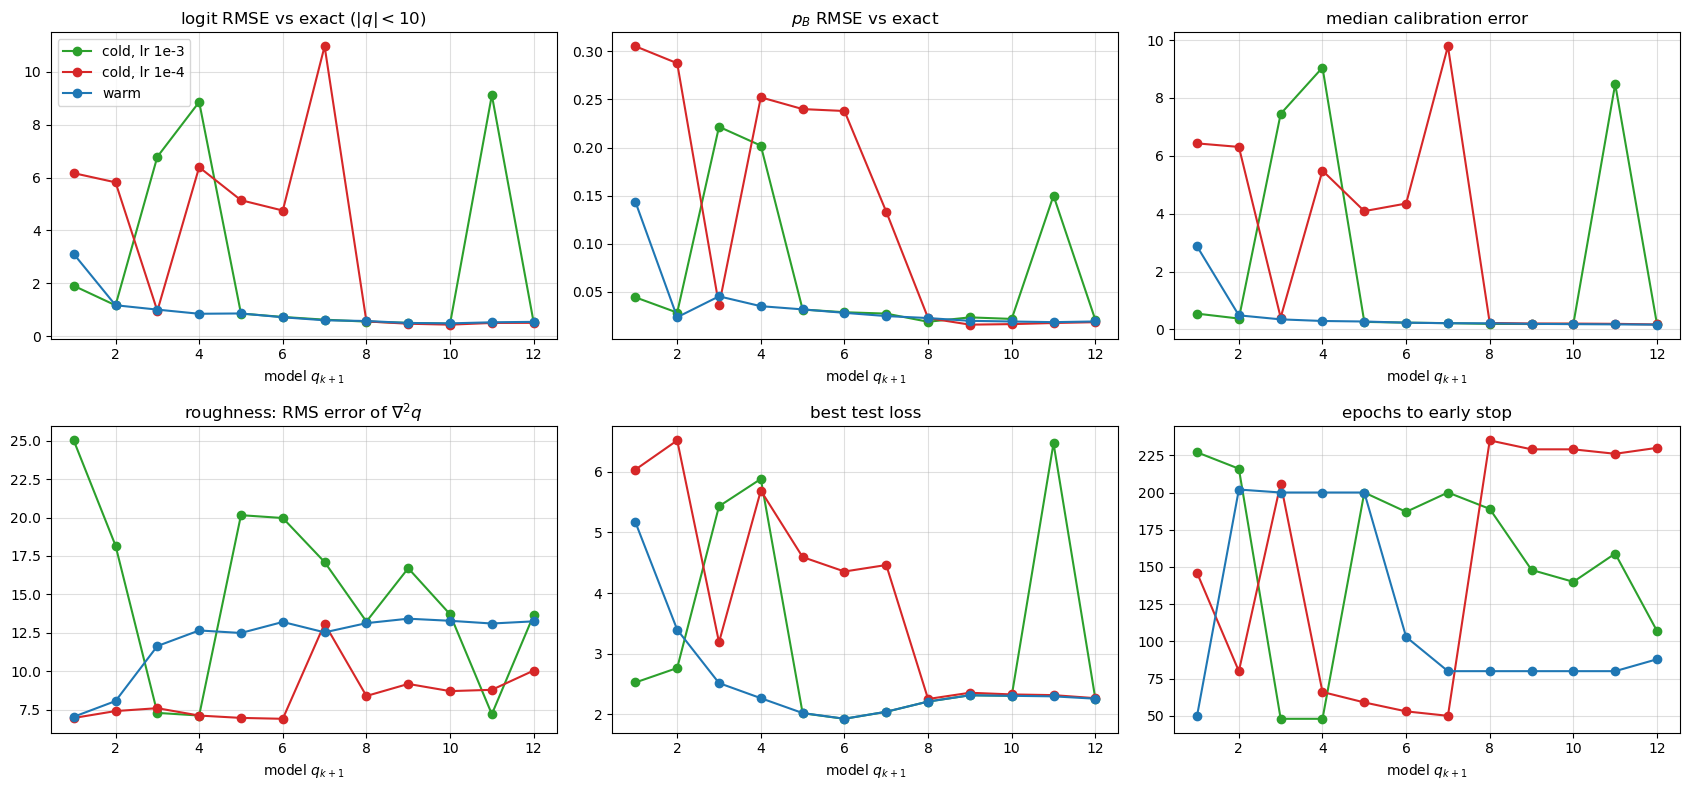

In [2]:
frames = []
for i, (name, d) in enumerate(COLD.items()):
    df = pd.read_csv(d / "metrics.csv")
    df["model"] = np.where(df["init"].str.startswith("warm"), "warm", name)
    frames.append(df if i == 0 else df[df["model"] != "warm"])   # warm rows once
m = pd.concat(frames)
m = m[m["iteration"].isin(ITS)].sort_values(["model", "iteration"])

panels = [("proj_rmse_logit", "logit RMSE vs exact ($|q|<10$)"), ("proj_rmse_pB", "$p_B$ RMSE vs exact"),
          ("calib_median", "median calibration error"), ("laplacian_err_rms", "roughness: RMS error of $\\nabla^2 q$"),
          ("best_test_loss", "best test loss"), ("epochs", "epochs to early stop")]
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, (col, title) in zip(axes.flat, panels):
    for name, g in m.groupby("model"):
        ax.plot(g["iteration"] + 1, g[col], "o-", color=COLORS[name], label=name)
    ax.set_title(title); ax.set_xlabel("model $q_{k+1}$"); ax.grid(alpha=0.4)
axes[0, 0].legend()
fig.tight_layout()

table = m.pivot(index="iteration", columns="model",
                values=["proj_rmse_logit", "proj_rmse_pB", "calib_median", "epochs"])
table.style.format(precision=3)

## 2. Stability between iterations
These are theory-free measures, so they're also available for a real system:
- **Δq between iterations:** the weighted RMS of $q_{k+1} - q_k$ on RPE$_k$ for $|q_k|<6$. This is the run's stopping rule, applied to each model chain.
- **Warm vs cold:** the weighted RMS of $q^{warm}_{k+1} - q^{cold}_{k+1}$ on the same frames. It measures how far apart the two trainings end on identical data.

**What to look for:** a warm-started chain should settle (Δq → 0). If the cold chain keeps a noise floor, that floor is the training-to-training spread on the same data. Δq can't fall below it.

,iteration,"warm − (cold, lr 1e-4)","warm − (cold, lr 1e-3)",Δq warm,"Δq cold, lr 1e-4","Δq cold, lr 1e-3"
0,0,4.686,2.483,nan,nan,nan
1,1,3.942,0.231,2.098,0.298,1.577
2,2,0.455,7.633,0.557,1.825,7.025
3,3,5.291,8.787,1.452,6.251,1.035
4,4,4.357,0.075,0.314,0.542,1.790
5,5,4.149,0.086,0.185,0.303,0.202
6,6,9.212,0.060,0.118,2.002,0.164
7,7,0.092,0.042,0.124,1.053,0.109
8,8,0.093,0.038,0.114,0.147,0.123
9,9,0.083,0.035,0.082,0.093,0.084


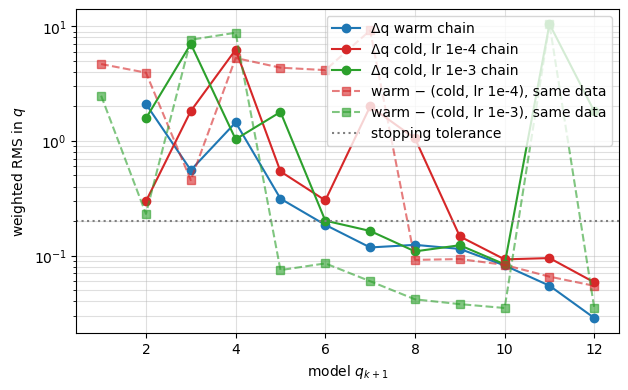

In [3]:
rows = []
for k in ITS:
    vis = vis_of(k)
    mk = models(k)
    row = {"iteration": k, **{f"warm − ({name})": dg.model_change(vis, mk["warm"], mk[name]) for name in COLD}}
    if k - 1 in ITS:   # previous model of each chain, scored on RPE_k
        prev = models(k - 1)
        row.update({f"Δq {name}": dg.model_change(vis, prev[name], mk[name]) for name in NAMES})
    rows.append(row)
stab = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 4.2))
for name in NAMES:
    ax.semilogy(stab["iteration"] + 1, stab[f"Δq {name}"], "o-", color=COLORS[name], label=f"Δq {name} chain")
for name in COLD:
    ax.semilogy(stab["iteration"] + 1, stab[f"warm − ({name})"], "s--", color=COLORS[name], alpha=0.6,
                label=f"warm − ({name}), same data")
ax.axhline(cfg["run"]["convergence"]["delta_q_tol"], color="grey", ls=":", label="stopping tolerance")
ax.set_xlabel("model $q_{k+1}$"); ax.set_ylabel("weighted RMS in $q$"); ax.grid(alpha=0.4, which="both"); ax.legend()
stab.style.format(precision=3)

## 3. Training curves
The test loss per epoch for both trainings on the same RPE$_k$. The warm start begins at the previous model's loss, the cold restart at a random network.

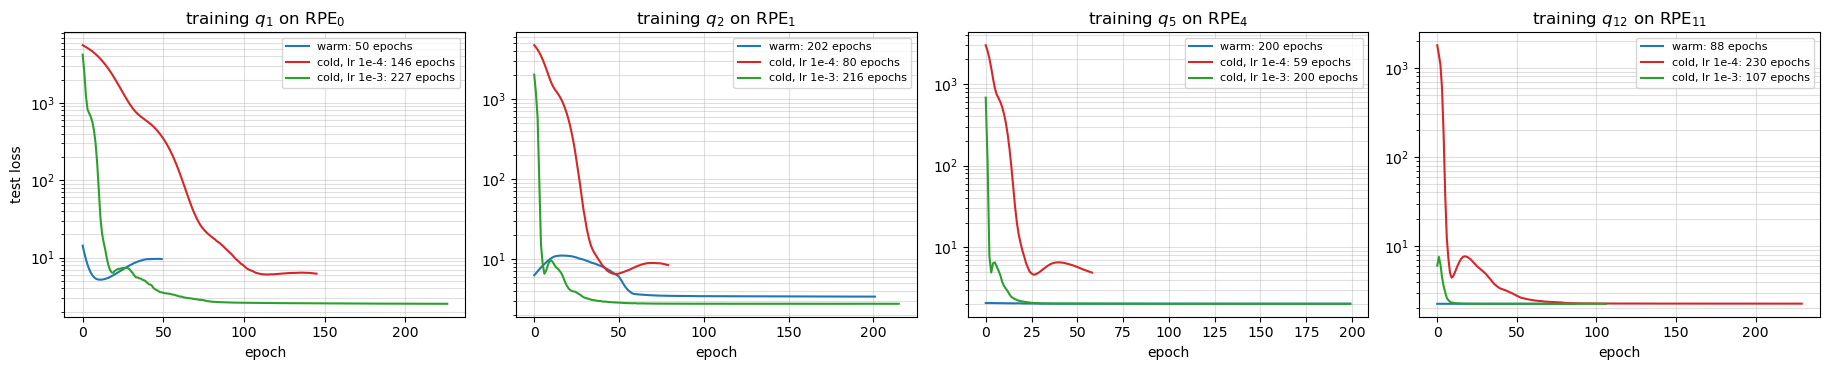

In [4]:
fig, axes = plt.subplots(1, len(SHOW), figsize=(4.6 * len(SHOW), 3.8), sharey=False)
for ax, k in zip(np.atleast_1d(axes), SHOW):
    for name in NAMES:
        h = json.loads((HIST[name] / f"training_it{k + 1}.json").read_text())
        ax.plot(h["test_total"], color=COLORS[name], label=f"{name}: {len(h['test_total'])} epochs")
    ax.set_title(f"training $q_{{{k + 1}}}$ on RPE$_{{{k}}}$"); ax.set_xlabel("epoch"); ax.set_yscale("log")
    ax.grid(alpha=0.4, which="both"); ax.legend(fontsize=8)
np.atleast_1d(axes)[0].set_ylabel("test loss")
fig.tight_layout()

## 4. Committor landscapes side by side
For each shown iteration:
- **Columns 1–2:** both models projected on the RPE frames in (x, y). In 22-D this is the weighted mean over the harmonic dimensions.
- **Columns 3–4:** the logit error against the exact committor, on the bins RPE$_k$ samples.

**What to look for:** the shape of the isocommittor lines in both channels, and where the error maps differ. Look especially at the sparsely sampled right channel and at the edges of the sampled region.

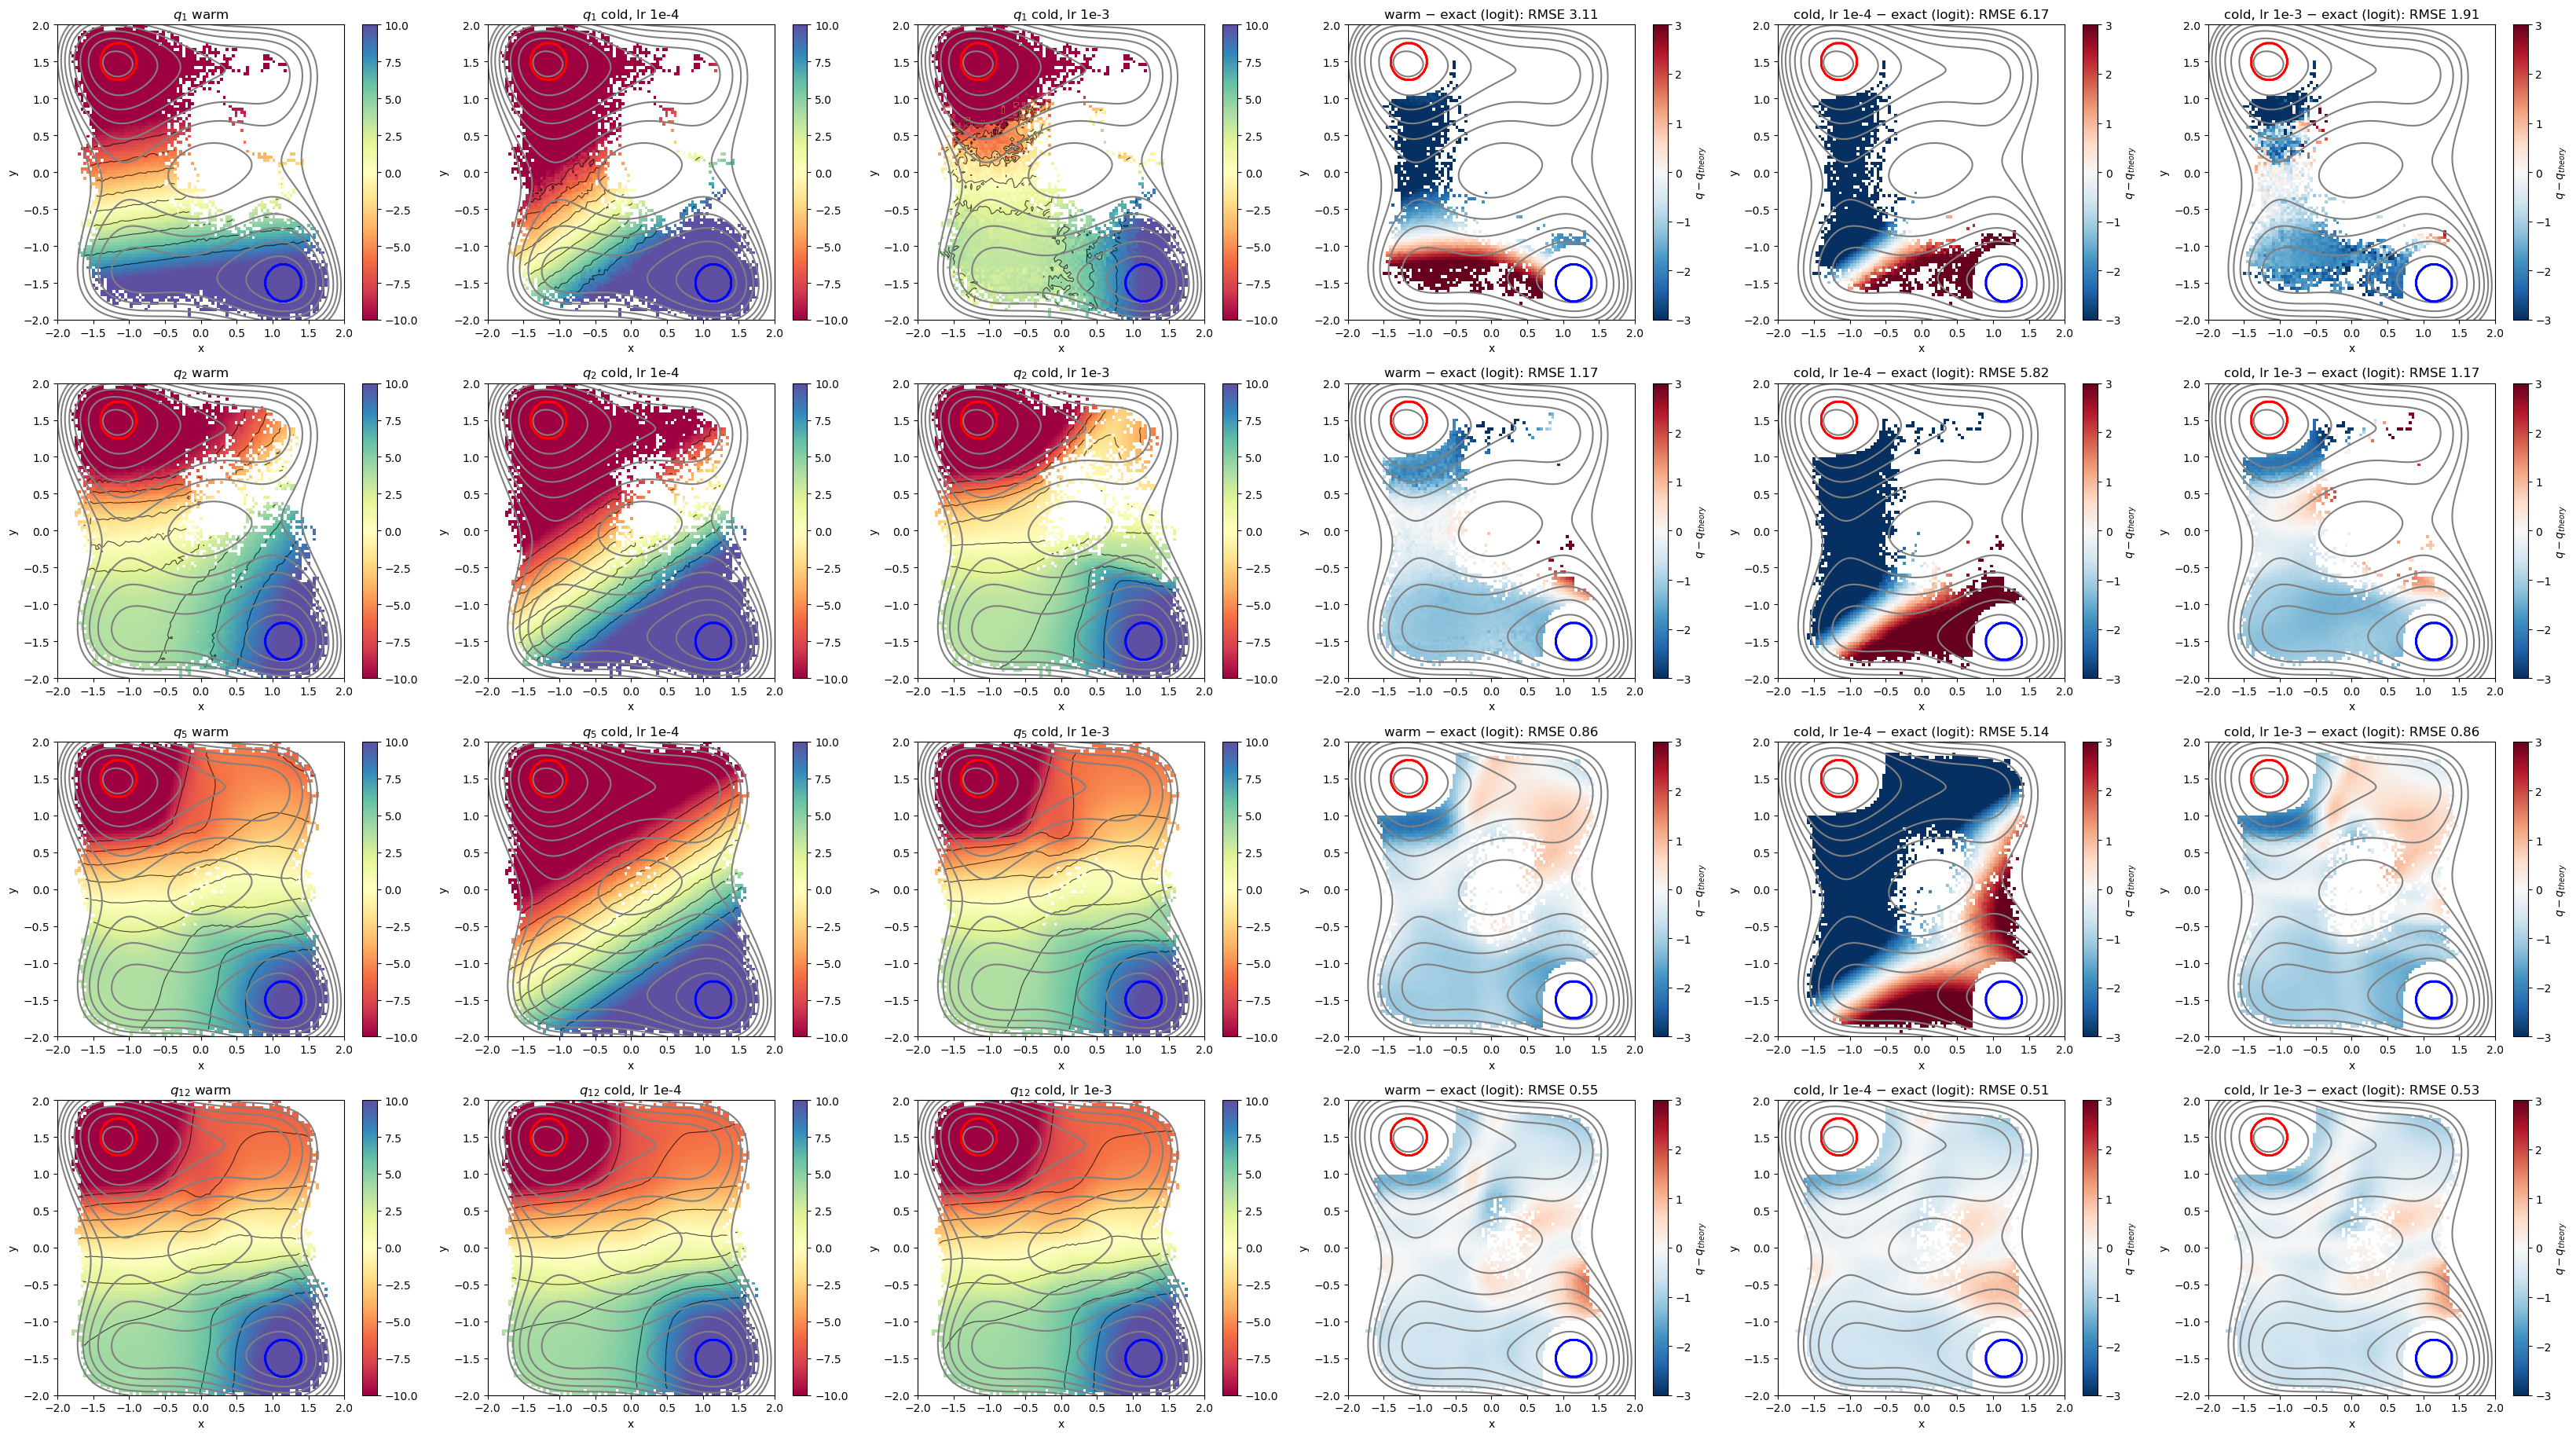

In [5]:
lim, levels = (-10, 10), np.arange(-8, 9, 2)
n = len(NAMES)
fig, axes = plt.subplots(len(SHOW), 2 * n, figsize=(5.5 * 2 * n, 4.6 * len(SHOW)))
for row, k in zip(np.atleast_2d(axes), SHOW):
    vis = vis_of(k)
    for j, (name, model) in enumerate(models(k).items()):
        ax = row[j]
        im = vis.plot_q_model_projection(model, n_bins_2d=acfg["n_bins_2d"], ax=ax, v_min_max=lim)
        vis.plot_q_model_projection_contours(model, n_bins_2d=acfg["n_bins_2d"], ax=ax, levels=levels)
        plt.colorbar(im, ax=ax)
        ax.set_title(f"$q_{{{k + 1}}}$ {name}")
        pr = vis.plot_committor_projection_error(model, ax=row[n + j], n_bins_2d=acfg["n_bins_2d"],
                                                 p_clip=dg.p_clip_of(acfg), min_count=acfg["min_count"])
        row[n + j].set_title(f"{name} − exact (logit): RMSE {pr['rmse_logit']:.2f}")
    for ax in row:
        dg._decorate(vis, ax)
        ax.set_xlim(vis.dims_extent[:2]); ax.set_ylim(vis.dims_extent[2:])
fig.tight_layout()

## 5. Calibration and chevron plot side by side
These are the theory-free validations against the RPE shot results (JCP 165, 124125).
- **Calibration:** binned logit $p_B^{RPE}$ against model $q$. On the diagonal means calibrated.
- **Chevron plot:** the loss and information along $q$, and $p_A$, $p_B$ against the logistic relation.

**What to look for:** a model can match the exact committor in the dense region and still be miscalibrated in the tails, where the RPE weights are small.

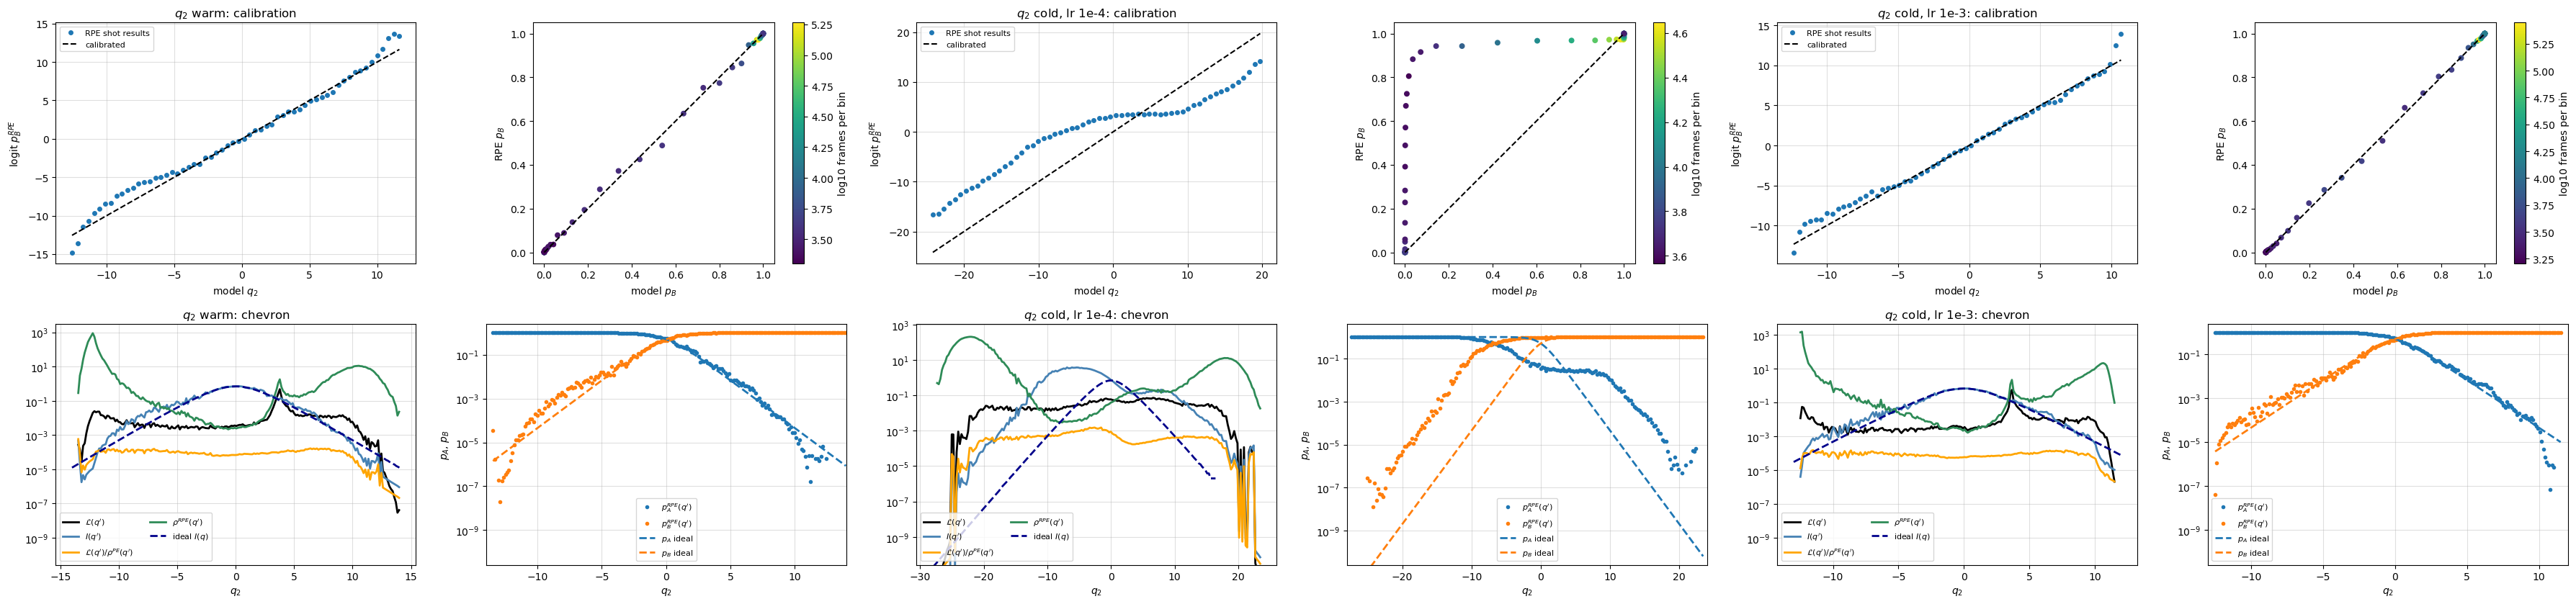

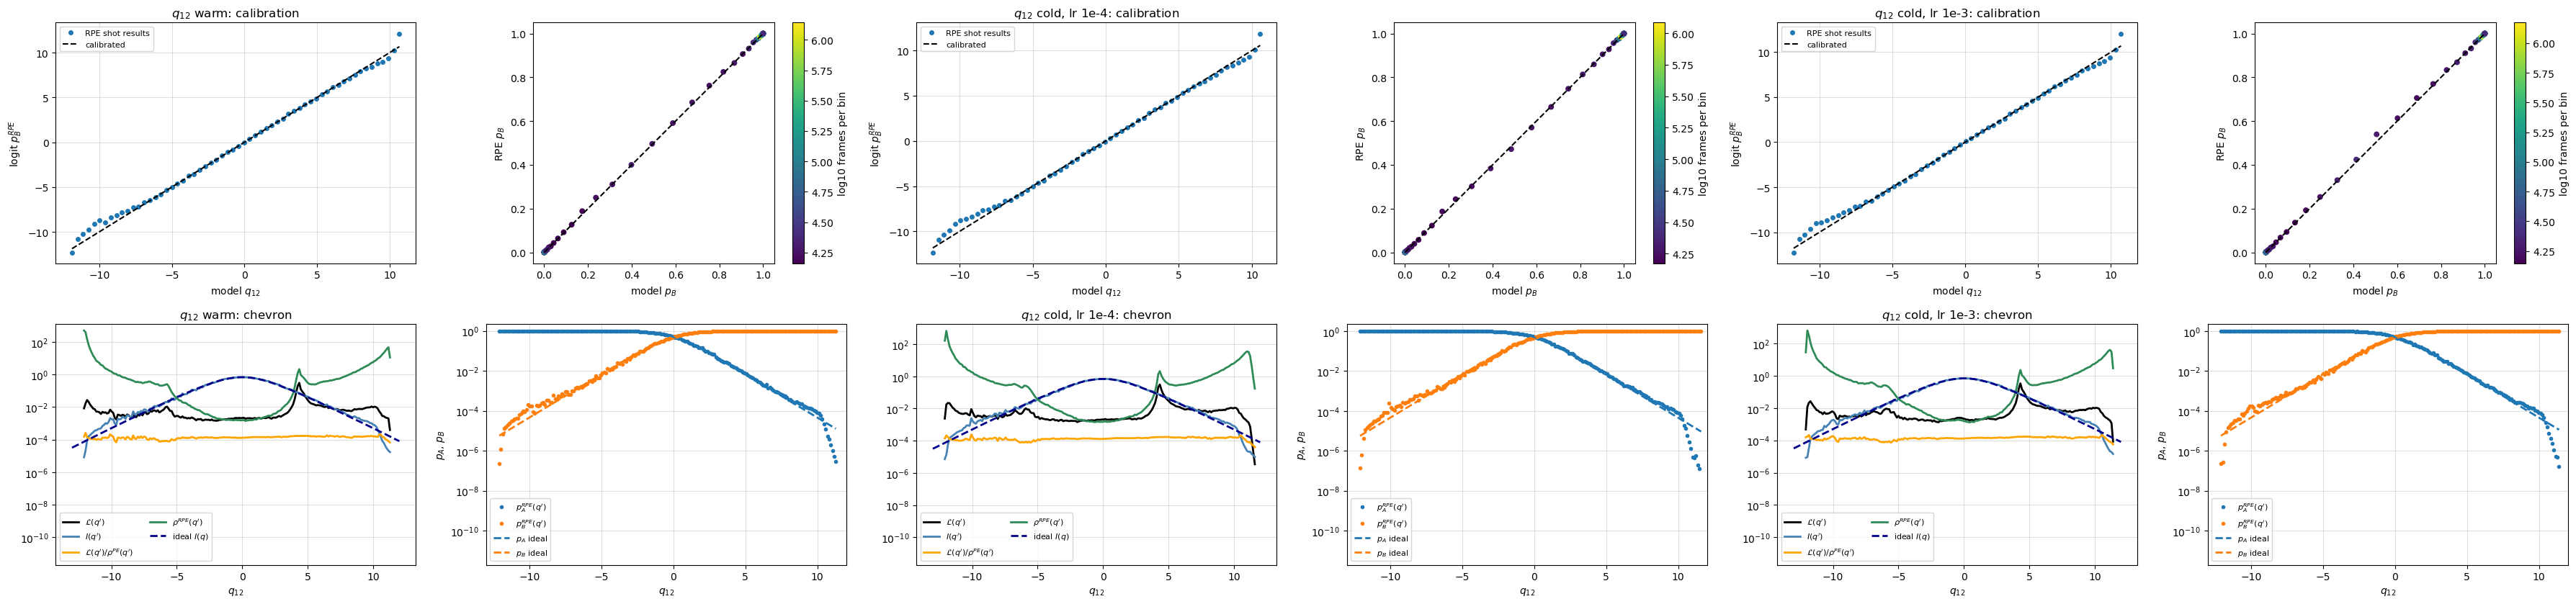

In [6]:
for k in (SHOW[1] if len(SHOW) > 1 else SHOW[0], LAST):
    fig, axes = plt.subplots(2, 2 * len(NAMES), figsize=(12 * len(NAMES), 8.5))
    for j, (name, model) in enumerate(models(k).items()):
        dg.plot_calibration(vis_of(k), model, axes=axes[0, 2 * j:2 * j + 2], label=f"q_{{{k + 1}}}")
        dg.plot_chevron(vis_of(k), model, axes=axes[1, 2 * j:2 * j + 2], n_bins_q=200, label=f"q_{{{k + 1}}}")
        axes[0, 2 * j].set_title(f"$q_{{{k + 1}}}$ {name}: calibration")
        axes[1, 2 * j].set_title(f"$q_{{{k + 1}}}$ {name}: chevron")
    fig.tight_layout()

## 6. Stochastic gates: which descriptors does each model use?
The deterministic gate value per descriptor is clamp(μ, 0, 1); 0 removes the input. Of the 22 inputs, only x and y carry committor information; h0–h19 are separable harmonic noise.

**What to look for:** both models should keep x and y open and close the harmonics. A warm start inherits the gates from earlier iterations. A cold restart has to rediscover them from a single RPE$_k$.

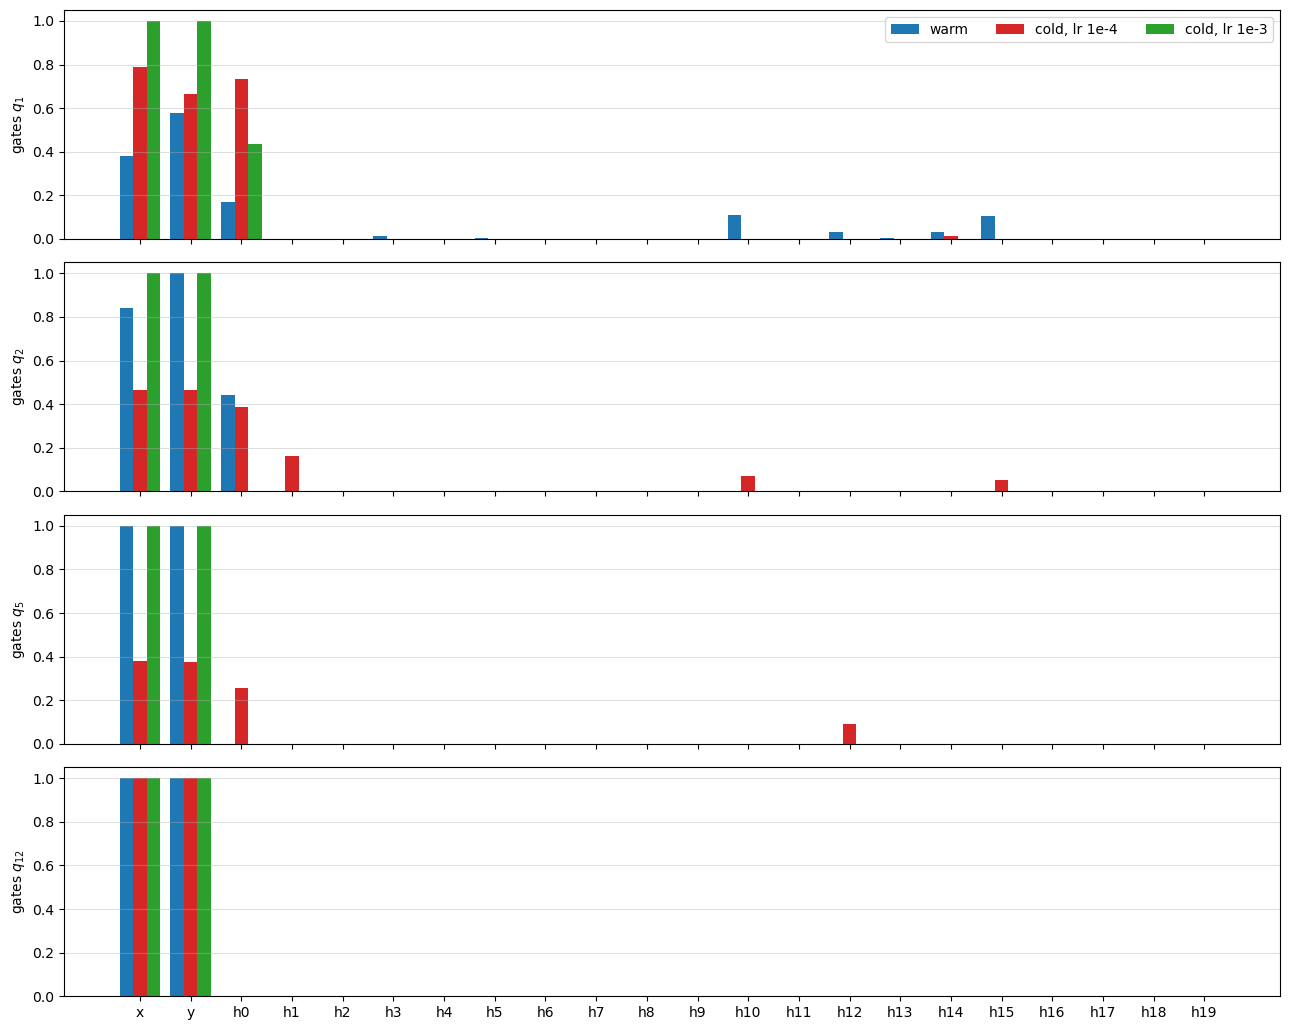

In [7]:
def gate_values(model):
    gates = [g for g in model.nnet.modules() if hasattr(g, "deterministic_gate_values")]
    return gates[0].deterministic_gate_values().detach().cpu().numpy() if gates else None

labels = ["x", "y"] + [f"h{i}" for i in range(vis_of(LAST)._desc.shape[1] - 2)]
fig, axes = plt.subplots(len(SHOW), 1, figsize=(13, 2.6 * len(SHOW)), sharex=True)
for ax, k in zip(np.atleast_1d(axes), SHOW):
    pos, width = np.arange(len(labels)), 0.8 / len(NAMES)
    for j, (name, model) in enumerate(models(k).items()):
        g = gate_values(model)
        if g is not None:
            ax.bar(pos + (j - (len(NAMES) - 1) / 2) * width, g, width=width, color=COLORS[name], label=name)
    ax.set_ylabel(f"gates $q_{{{k + 1}}}$"); ax.set_ylim(0, 1.05); ax.grid(alpha=0.4, axis="y")
np.atleast_1d(axes)[0].legend(ncol=len(NAMES))
np.atleast_1d(axes)[-1].set_xticks(np.arange(len(labels)), labels)
fig.tight_layout()

## 7. Mechanism along $q$: gradient magnitude and unit-gradient components
These plots show which descriptors change the committor at each value of $q$, for the last training set. Weight on the harmonics in the unit gradient means the model uses noise dimensions. One figure per model: the warm-started one first, then each cold restart.

/Users/rbreeba/code/aimmd-tis/src/aimmdTIS/visualization/model_analysis.py:1181: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


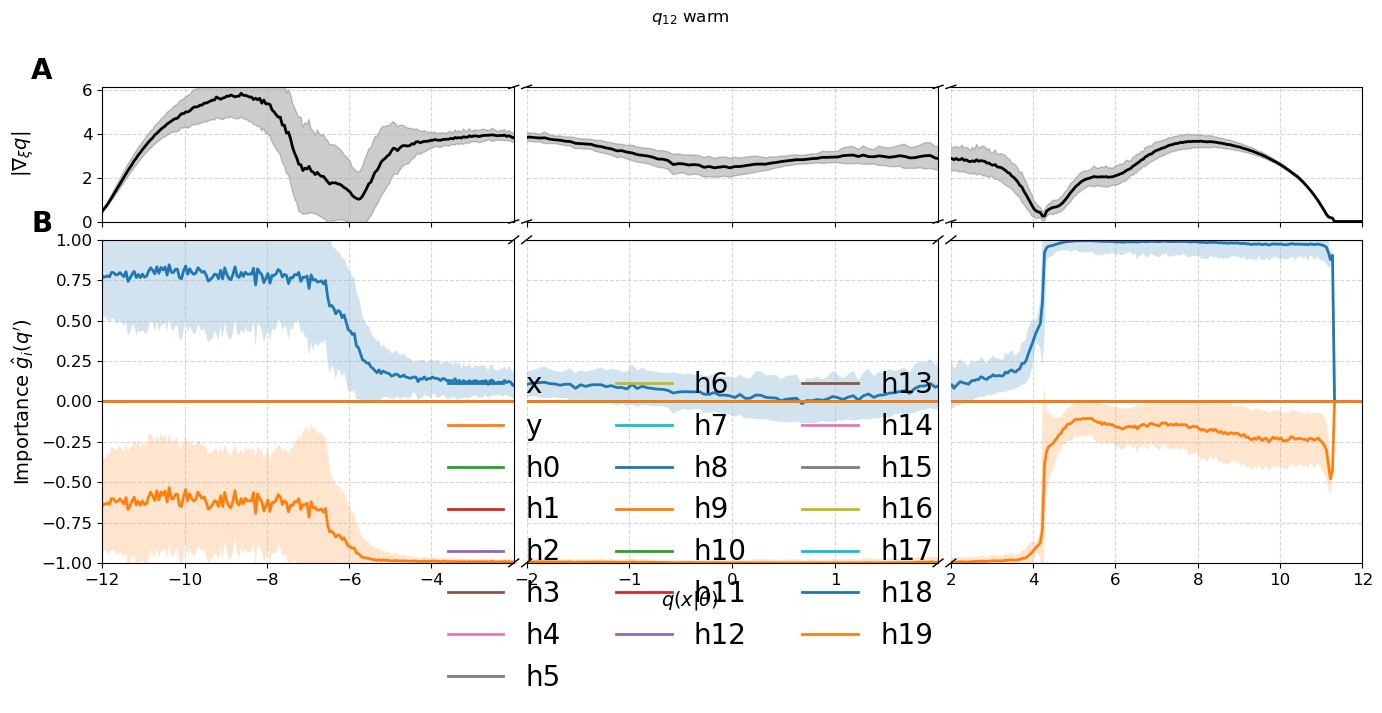

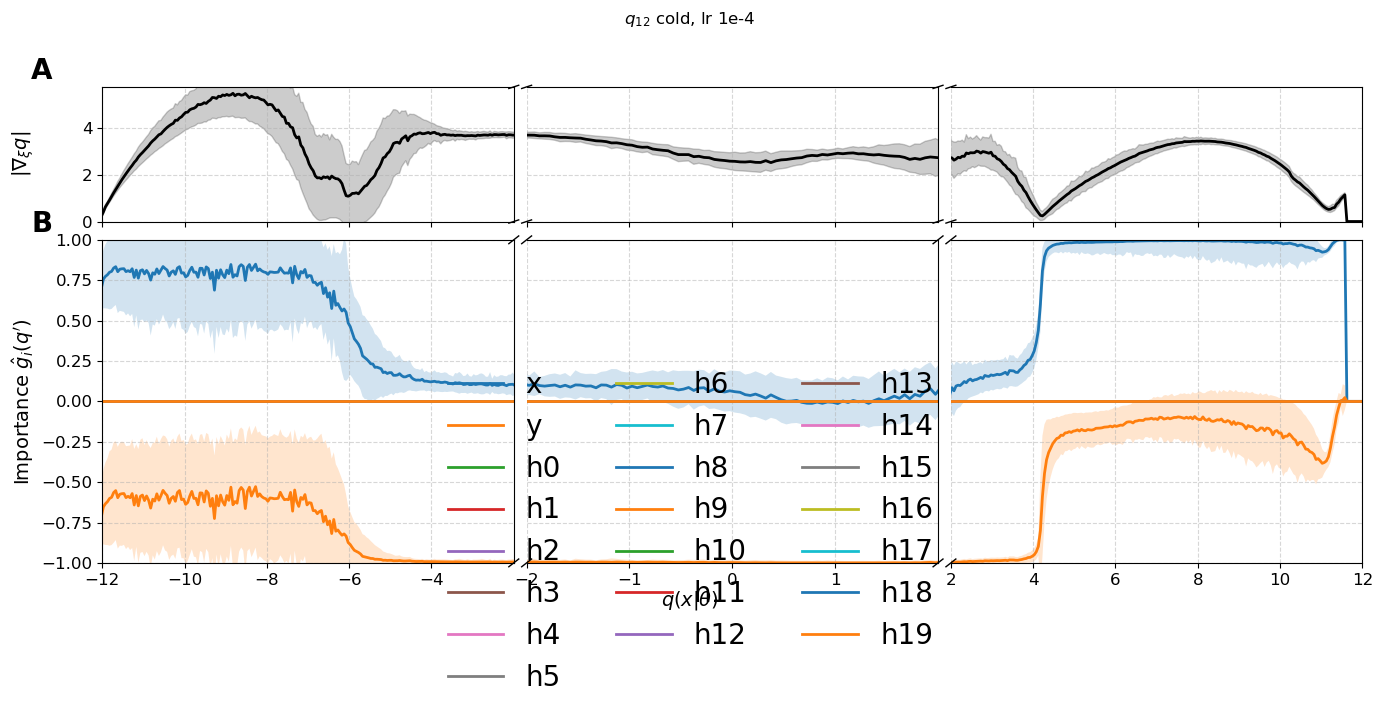

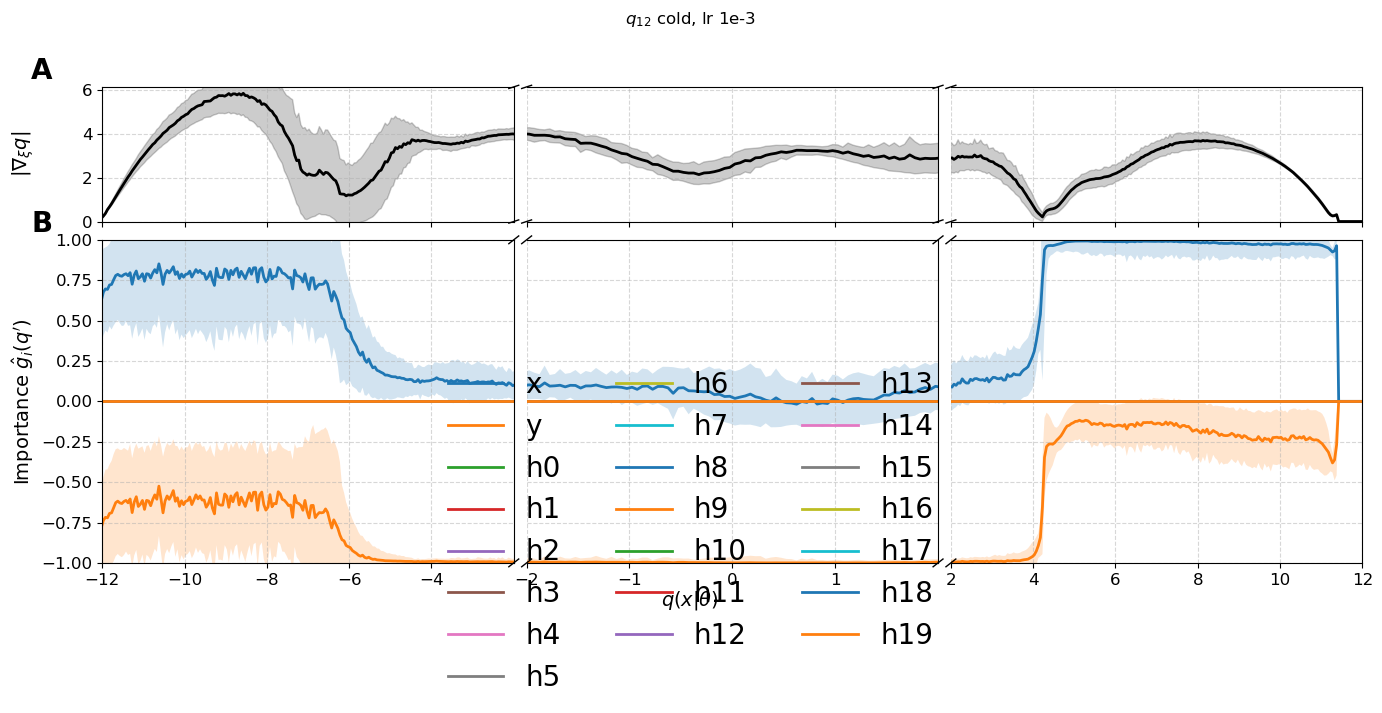

In [8]:
for name, model in models(LAST).items():
    fig = dg.plot_gradients(vis_of(LAST), model, q_range=tuple(acfg["grad_q_range"]))
    fig.suptitle(f"$q_{{{LAST + 1}}}$ {name}", y=1.01)